# Car Prediction Project

## Step 1: Data Understanding & Preprocessing

In [27]:
import pandas as pd

path = r"https://raw.githubusercontent.com/sahilchavan08/Datasets/refs/heads/main/car_price_prediction.csv"

df = pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [28]:
df.shape

(19237, 18)

In [29]:
df.columns.tolist()

['ID',
 'Price',
 'Levy',
 'Manufacturer',
 'Model',
 'Prod. year',
 'Category',
 'Leather interior',
 'Fuel type',
 'Engine volume',
 'Mileage',
 'Cylinders',
 'Gear box type',
 'Drive wheels',
 'Doors',
 'Wheel',
 'Color',
 'Airbags']

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [31]:
df.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [32]:
df.isnull().sum().sum()

np.int64(0)

In [33]:
 df.duplicated().sum()

np.int64(313)

In [34]:
df = df.drop_duplicates()

In [35]:
df.duplicated().sum()

np.int64(0)

**Convert categorical variables (Fuel_Type, Mileage, Airbags) into numerical format.**

In [36]:
# Convert Mileage to Numeric Format
df['Mileage'] = pd.to_numeric(
    df['Mileage'].astype(str).str.replace(' km', '', regex=False),
    errors='coerce'
)

print(df['Mileage'].dtype)
display(df[['Mileage']].head())

int64


,Mileage
0,186005
1,192000
2,200000
3,168966
4,91901


In [37]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Fuel type'] = le.fit_transform(df['Fuel type'].astype(str))

print("Fuel type converted to numerical format")
display(df[['Fuel type']].head())

Fuel type converted to numerical format


,Fuel type
0,2
1,5
2,5
3,2
4,5


In [38]:
print("Airbags Data Type:", df['Airbags'].dtype)
display(df[['Airbags']].head())

Airbags Data Type: int64


,Airbags
0,12
1,8
2,2
3,0
4,4


In [39]:
# Convert '-' in Levy to missing values
df['Levy'] = df['Levy'].replace('-', pd.NA)

# Convert Levy to numeric
df['Levy'] = pd.to_numeric(df['Levy'], errors='coerce')

# Convert Engine volume to numeric
df['Engine volume'] = pd.to_numeric(
    df['Engine volume'].astype(str).str.replace(' Turbo', '', regex=False),
    errors='coerce'
)

print("Levy Data Type:", df['Levy'].dtype)
print("Engine Volume Data Type:", df['Engine volume'].dtype)

print("\nMissing values after cleaning:")
print(df[['Levy', 'Engine volume']].isnull().sum())

display(df[['Levy', 'Engine volume']].head(10))

Levy Data Type: float64
Engine Volume Data Type: float64

Missing values after cleaning:
Levy             5709
Engine volume       0
dtype: int64


,Levy,Engine volume
0,1399.0,3.5
1,1018.0,3.0
2,NaN,1.3
3,862.0,2.5
4,446.0,1.3
5,891.0,2.0
6,761.0,1.8
7,751.0,2.4
8,394.0,2.5
9,NaN,3.5


## Step 2: Exploratory Data Analysis (EDA)

•	Generate descriptive statistics.

•	Create visualizations (histograms, scatter plots, boxplots, correlation heatmap).

•	Identify relationships between independent variables and selling price.


**Generate Descriptive Statistics**

In [40]:
df.describe()

,ID,Price,Levy,Prod. year,Fuel type,Engine volume,Mileage,Cylinders,Airbags
count,1.892400e+04,1.892400e+04,13215.000000,18924.000000,18924.000000,18924.000000,1.892400e+04,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,906.299205,2010.914236,3.426971,2.306251,1.555373e+06,4.580216,6.568379
std,9.375468e+05,1.921356e+05,463.296871,5.665749,1.806295,0.877591,4.880221e+07,1.200223,4.322323
min,2.074688e+07,1.000000e+00,87.000000,1939.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000
25%,4.569501e+07,5.331000e+03,640.000000,2009.000000,2.000000,1.800000,7.019575e+04,4.000000,4.000000
50%,4.577191e+07,1.317200e+04,781.000000,2012.000000,5.000000,2.000000,1.264000e+05,4.000000,6.000000
75%,4.580174e+07,2.206300e+04,1058.000000,2015.000000,5.000000,2.500000,1.891198e+05,4.000000,12.000000
max,4.581665e+07,2.630750e+07,11714.000000,2020.000000,6.000000,20.000000,2.147484e+09,16.000000,16.000000


**Histogram**

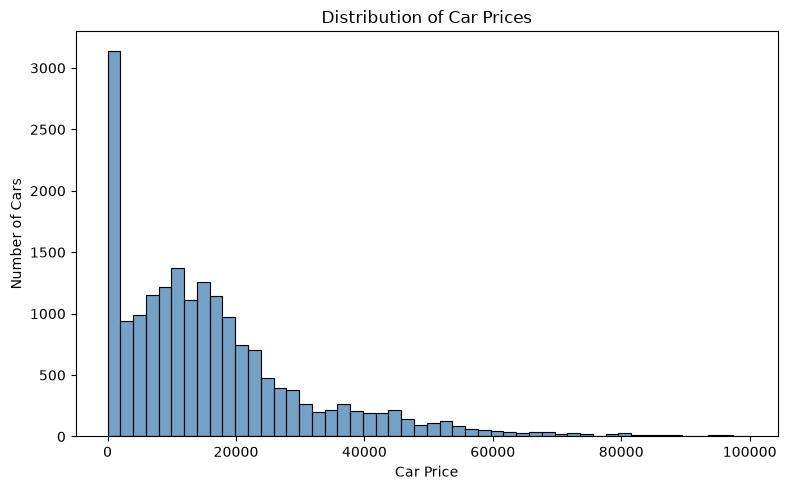

In [42]:
import seaborn as sns
import matplotlib.pylab as plt
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df[df['Price'] <= 100000],
    x='Price',
    bins=50,
    color='steelblue'
)

plt.title('Distribution of Car Prices')
plt.xlabel('Car Price')
plt.ylabel('Number of Cars')

plt.tight_layout()
plt.show()

The histogram shows that most cars have prices in the lower price range. As the car price increases, the number of cars generally decreases. The distribution is right-skewed because a small number of cars have very high prices. This graph helps us understand the price distribution and identify potential outliers.

**Scatter Plot**

Car Price vs Mileage

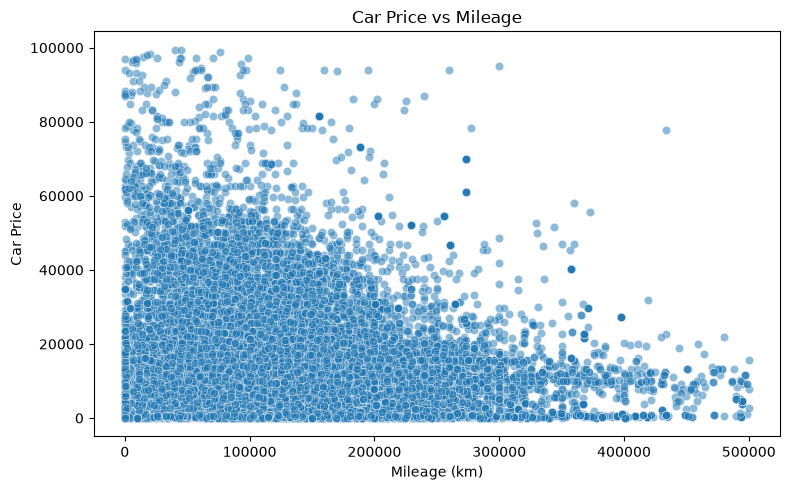

In [43]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df[
        (df['Mileage'] <= 500000) &
        (df['Price'] <= 100000)
    ],
    x='Mileage',
    y='Price',
    alpha=0.5
)

plt.title('Car Price vs Mileage')
plt.xlabel('Mileage (km)')
plt.ylabel('Car Price')

plt.tight_layout()
plt.show()

The scatter plot shows the relationship between car mileage and car price. Many cars with lower mileage have a wide range of prices, while cars with higher mileage are mostly concentrated in lower price ranges. This suggests a possible negative relationship between mileage and car price. However, other factors also affect car prices.

**Box Plot**

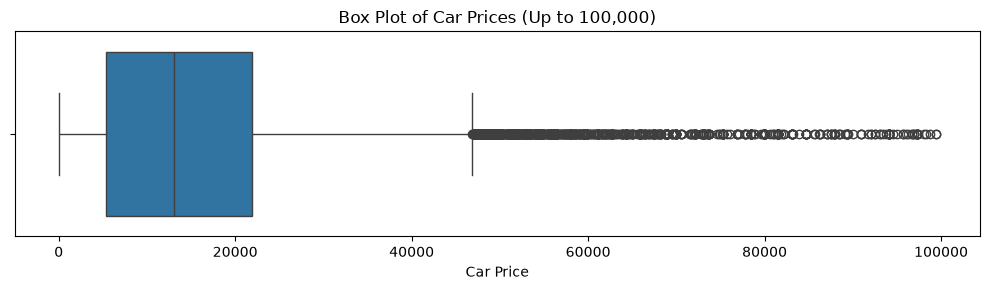

In [44]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=df.loc[df['Price'] <= 100000, 'Price']
)

plt.title('Box Plot of Car Prices (Up to 100,000)')
plt.xlabel('Car Price')

plt.tight_layout()
plt.show()

The box plot shows the distribution and spread of car prices. The line inside the box represents the median price. The box shows the middle 50% of the prices, while the points beyond the whiskers represent potential outliers. These outliers may indicate cars with unusually high prices compared to most cars in the dataset.

**Correlation Heatmap**

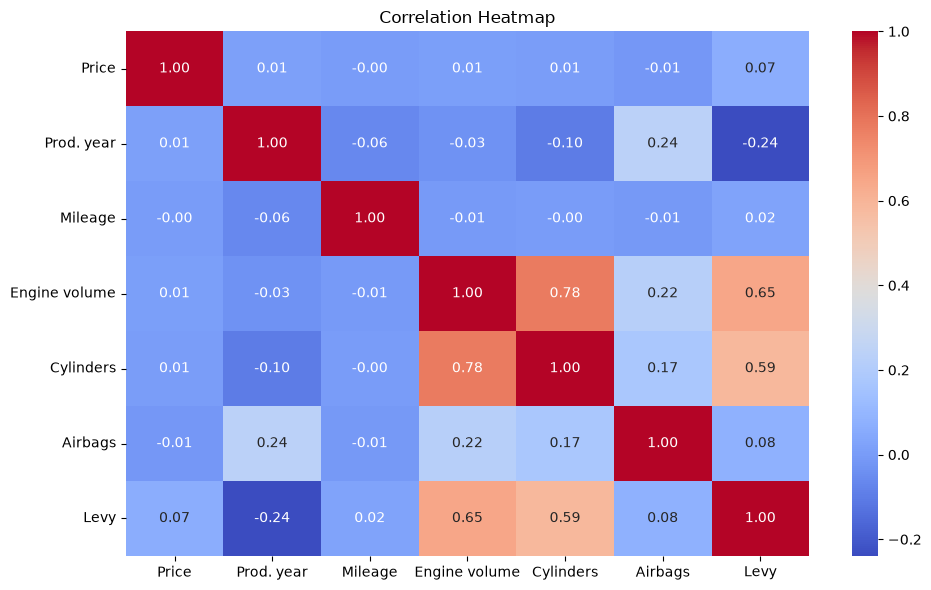

In [45]:
plt.figure(figsize=(10, 6))

cols = [
    'Price',
    'Prod. year',
    'Mileage',
    'Engine volume',
    'Cylinders',
    'Airbags',
    'Levy'
]

corr = df[cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

The heatmap shows the relationships between numerical variables. Positive values indicate a positive relationship, while negative values indicate a negative relationship. It helps identify variables related to car prices.

**Identify Relationships Between Independent Variables and Selling Price**

In [46]:
price_corr = df[cols].corr()['Price'].sort_values(ascending=False)

print(price_corr)

Price            1.000000
Levy             0.065458
Prod. year       0.012689
Engine volume    0.008888
Cylinders        0.007435
Mileage         -0.001763
Airbags         -0.012709
Name: Price, dtype: float64


## Step 3: Model Development
•	Split dataset into train and test sets.

•	Build a Linear Regression model to predict selling price.

•	Train the model on training data.

•	Test the model on unseen test data.


**Data cleaning**

In [47]:
print("Mileage above 500000:",
      (df['Mileage'] > 500000).sum())

print("Price above 100000:",
      (df['Price'] > 100000).sum())

Mileage above 500000: 254
Price above 100000: 111


In [48]:
df_model = df.copy()


df_model.loc[df_model['Mileage'] > 500000, 'Mileage'] = np.nan

df_model = df_model[df_model['Price'] <= 100000].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_model.shape)
print("Missing Mileage:", df_model['Mileage'].isnull().sum())

Original dataset: (18924, 18)
Cleaned dataset: (18813, 18)
Missing Mileage: 254


In [49]:
X = df_model[
    ['Prod. year', 'Engine volume', 'Mileage',
     'Cylinders', 'Airbags', 'Levy']
]

y = df_model['Price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (18813, 6)
y shape: (18813,)


**Split Dataset into Train and Test Sets**

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (15050, 6)
Testing data: (3763, 6)


**Linear regression using pipeline**

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', LinearRegression())
])

pipeline.fit(X_train, y_train)

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Prod. year','Engine volume','Mileage','Cylinders','Airbags','Levy']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"

## Algorithm Evaluation

In [52]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error

### Algorithm Evaluation — Models

In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

dct = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

dct.items()

dict_items([('Linear Regression', LinearRegression()), ('Decision Tree', DecisionTreeRegressor(random_state=42)), ('Random Forest', RandomForestRegressor(random_state=42)), ('Gradient Boosting', GradientBoostingRegressor(random_state=42)), ('XGBoost', XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...))])

### models train

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2_scores = []
mae_scores = []
rmse_scores = []

for name, model in dct.items():

    pipeline_model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', model)
    ])

    pipeline_model.fit(X_train, y_train)

    ypred_test = pipeline_model.predict(X_test)

    r2_scores.append(round(r2_score(y_test, ypred_test), 4))
    mae_scores.append(round(mean_absolute_error(y_test, ypred_test), 2))
    rmse_scores.append(round(np.sqrt(mean_squared_error(y_test, ypred_test)), 2))

print("R2 Scores:", r2_scores)
print("MAE Scores:", mae_scores)
print("RMSE Scores:", rmse_scores)

R2 Scores: [0.1612, 0.4369, 0.5983, 0.4662, 0.5864]
MAE Scores: [10361.44, 6452.49, 5562.09, 7756.74, 6376.81]
RMSE Scores: [np.float64(14448.58), np.float64(11837.81), np.float64(9998.75), np.float64(11525.7), np.float64(10144.93)]


### DataFrame

In [57]:
res = {
    'Algorithm': list(dct.keys()),
    'R2 Score': r2_scores,
    'MAE': mae_scores,
    'RMSE': rmse_scores
}

df_res = pd.DataFrame(res)

df_res.sort_values(
    by='R2 Score',
    ascending=False
)

,Algorithm,R2 Score,MAE,RMSE
2,Random Forest,0.5983,5562.09,9998.75
4,XGBoost,0.5864,6376.81,10144.93
3,Gradient Boosting,0.4662,7756.74,11525.70
1,Decision Tree,0.4369,6452.49,11837.81
0,Linear Regression,0.1612,10361.44,14448.58


## XGBoost model

In [59]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

pipeline_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', model)
])

pipeline_xgb.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


### XGBoost Model Evaluation

In [60]:
y_pred_xgb = pipeline_xgb.predict(X_test)

print("XGBoost R2 Score:", r2_score(y_test, y_pred_xgb))

print("XGBoost MAE:",
      mean_absolute_error(y_test, y_pred_xgb))

print("XGBoost RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_xgb)))

XGBoost R2 Score: 0.5864469408988953
XGBoost MAE: 6376.814453125
XGBoost RMSE: 10144.932922400227


## Hyperparameter Tuning

In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20, None]
}

base_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

gscv = GridSearchCV(
    estimator=base_model,
    param_grid=params,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

gscv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 20, ...], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of in

In [64]:
print("Best Parameters:", gscv.best_params_)
print("Best CV R2 Score:", gscv.best_score_)

Best Parameters: {'model__max_depth': 20, 'model__n_estimators': 200}
Best CV R2 Score: 0.6029384547509125


## Final Model Evaluation

In [65]:
best_model = gscv.best_estimator_

y_pred_best = best_model.predict(X_test)

print("Final R2 Score:", r2_score(y_test, y_pred_best))
print("Final MAE:", mean_absolute_error(y_test, y_pred_best))
print("Final RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))

Final R2 Score: 0.6031070723211538
Final MAE: 5557.583736996106
Final RMSE: 9938.48655608218


**Test the model on unseen test data.**

In [66]:
y_pred = pipeline.predict(X_test)

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred.round(2)
})

result.head()

,Actual Price,Predicted Price
0,17876,18863.62
1,60831,25054.78
2,17562,21091.70
3,282,18877.14
4,32744,22086.46


## Conclusion

In this Car Price Prediction project, I performed data cleaning, exploratory data analysis, feature selection, and model development. I evaluated Linear Regression, Decision Tree, Random Forest, Gradient Boosting, and XGBoost regression algorithms using R² Score, MAE, and RMSE.

Random Forest achieved the best initial test performance, with an R² score of 0.5983. I then applied GridSearchCV for hyperparameter tuning and obtained the best parameters: `n_estimators=200` and `max_depth=20`. The best cross-validation R² score was approximately 0.603.

This project helped me understand regression algorithms, model evaluation, and hyperparameter tuning for predicting car prices.